In [2]:
%pip install opencv-python tensorflow -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Handwriting-Based Personality Detection using ResNet

This notebook builds a deep learning model to predict personality traits (Big Five) based on handwriting images using ResNet architecture combined with dense layers for improved feature extraction.

In [3]:
# Import Required Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Deep Learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, ResNet152
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.20.0
GPU Available: []


## 1. Load and Explore the Dataset

Extract and load the handwriting dataset from the archive folder. Explore the dataset structure, image dimensions, personality classes, and data distribution.

In [4]:
# Define dataset paths
dataset_path = Path(r'c:\Users\iquan\OneDrive\Desktop\Aditya Mishra\archive')
train_path = dataset_path / 'augmented train'
test_path = dataset_path / 'augmented test'

# Personality classes (Big Five)
personality_classes = ['Agreeableness', 'Conscientiousness', 'Extraversion', 'Neuroticism', 'Openness']

print(f"Dataset Root: {dataset_path}")
print(f"Training Data Path: {train_path}")
print(f"Test Data Path: {test_path}")
print(f"\nPersonality Classes: {personality_classes}")

# Check directory structure
print("\n--- Training Data Structure ---")
for personality in personality_classes:
    path = train_path / personality
    if path.exists():
        num_images = len(list(path.glob('*.*')))
        print(f"{personality}: {num_images} images")

print("\n--- Test Data Structure ---")
for personality in personality_classes:
    path = test_path / personality
    if path.exists():
        num_images = len(list(path.glob('*.*')))
        print(f"{personality}: {num_images} images")

Dataset Root: c:\Users\iquan\OneDrive\Desktop\Aditya Mishra\archive
Training Data Path: c:\Users\iquan\OneDrive\Desktop\Aditya Mishra\archive\augmented train
Test Data Path: c:\Users\iquan\OneDrive\Desktop\Aditya Mishra\archive\augmented test

Personality Classes: ['Agreeableness', 'Conscientiousness', 'Extraversion', 'Neuroticism', 'Openness']

--- Training Data Structure ---
Agreeableness: 720 images
Conscientiousness: 648 images
Extraversion: 576 images
Neuroticism: 864 images
Openness: 608 images

--- Test Data Structure ---
Agreeableness: 137 images
Conscientiousness: 131 images
Extraversion: 112 images
Neuroticism: 136 images
Openness: 144 images


In [5]:
# Load images and labels
def load_images_from_directory(directory, label_index, personality_classes):
    """Load all images from a directory with their corresponding labels"""
    images = []
    labels = []
    
    # Read all files from the personality class folder
    image_files = list(Path(directory).glob('*.*'))
    
    for img_path in image_files:
        try:
            # Read image
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                images.append(img)
                labels.append(label_index)
        except Exception as e:
            print(f"Error loading {img_path}: {e}")
    
    return images, labels

# Load training data
train_images = []
train_labels = []

for idx, personality in enumerate(personality_classes):
    path = train_path / personality
    if path.exists():
        imgs, lbls = load_images_from_directory(path, idx, personality_classes)
        train_images.extend(imgs)
        train_labels.extend(lbls)
        print(f"Loaded {len(imgs)} images for {personality}")

# Load test data
test_images = []
test_labels = []

for idx, personality in enumerate(personality_classes):
    path = test_path / personality
    if path.exists():
        imgs, lbls = load_images_from_directory(path, idx, personality_classes)
        test_images.extend(imgs)
        test_labels.extend(lbls)
        print(f"Loaded {len(imgs)} test images for {personality}")

print(f"\nTotal Training Images: {len(train_images)}")
print(f"Total Test Images: {len(test_images)}")

# Convert to numpy arrays
train_images = np.array(train_images)
train_labels = np.array(train_labels)
test_images = np.array(test_images)
test_labels = np.array(test_labels)

print(f"\nTrain Images Shape: {train_images.shape}")
print(f"Train Labels Shape: {train_labels.shape}")
print(f"Test Images Shape: {test_images.shape}")
print(f"Test Labels Shape: {test_labels.shape}")

Loaded 720 images for Agreeableness
Loaded 648 images for Conscientiousness
Loaded 648 images for Conscientiousness
Loaded 576 images for Extraversion
Loaded 576 images for Extraversion
Loaded 864 images for Neuroticism
Loaded 864 images for Neuroticism
Loaded 608 images for Openness
Loaded 608 images for Openness
Loaded 137 test images for Agreeableness
Loaded 137 test images for Agreeableness
Loaded 131 test images for Conscientiousness
Loaded 131 test images for Conscientiousness
Loaded 112 test images for Extraversion
Loaded 112 test images for Extraversion
Loaded 136 test images for Neuroticism
Loaded 136 test images for Neuroticism
Loaded 144 test images for Openness

Total Training Images: 3416
Total Test Images: 660
Loaded 144 test images for Openness

Total Training Images: 3416
Total Test Images: 660

Train Images Shape: (3416, 1024, 1024)
Train Labels Shape: (3416,)
Test Images Shape: (660, 1024, 1024)
Test Labels Shape: (660,)

Train Images Shape: (3416, 1024, 1024)
Train L

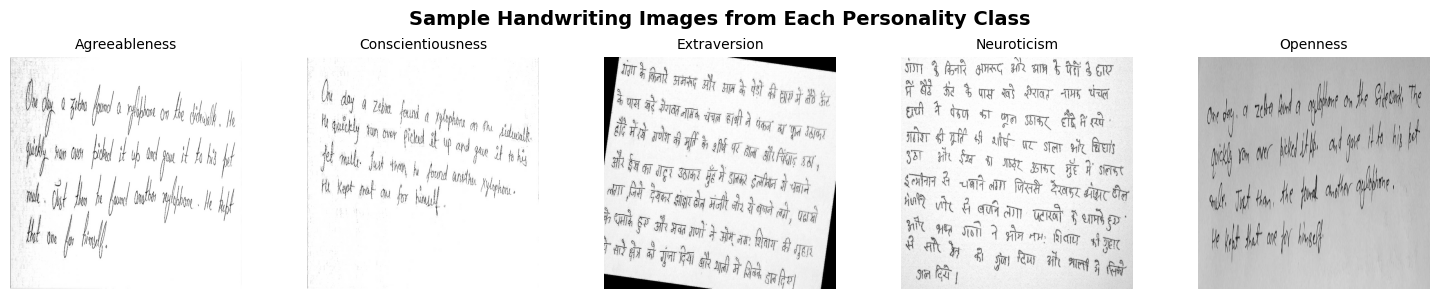

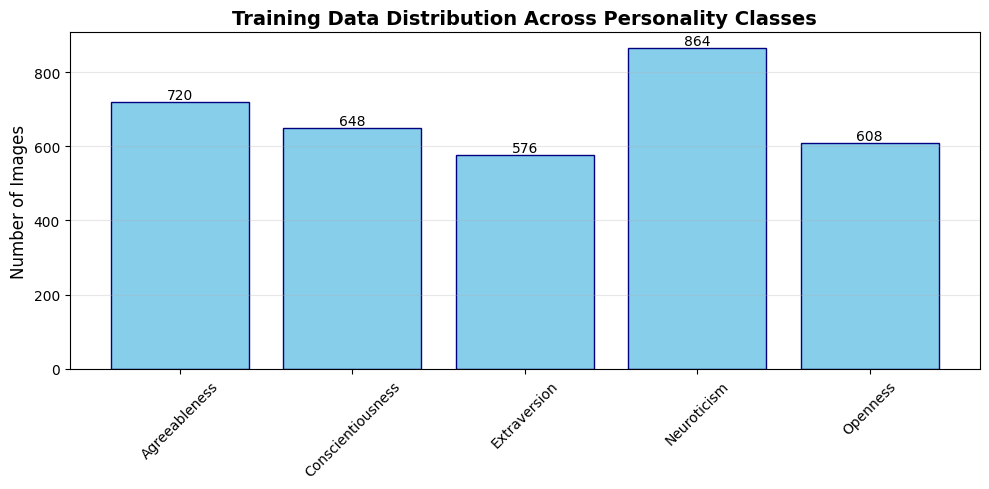


Data Distribution:
Agreeableness: 720 (21.1%)
Conscientiousness: 648 (19.0%)
Extraversion: 576 (16.9%)
Neuroticism: 864 (25.3%)
Openness: 608 (17.8%)


In [6]:
# Visualize sample images from each personality class
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
fig.suptitle('Sample Handwriting Images from Each Personality Class', fontsize=14, fontweight='bold')

for idx, personality in enumerate(personality_classes):
    # Find first image of this personality class
    class_indices = np.where(train_labels == idx)[0]
    if len(class_indices) > 0:
        sample_img = train_images[class_indices[0]]
        axes[idx].imshow(sample_img, cmap='gray')
        axes[idx].set_title(personality, fontsize=10)
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# Plot data distribution
class_counts = pd.Series(train_labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar([personality_classes[i] for i in class_counts.index], class_counts.values, color='skyblue', edgecolor='navy')
ax.set_ylabel('Number of Images', fontsize=12)
ax.set_title('Training Data Distribution Across Personality Classes', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"\nData Distribution:")
for i, personality in enumerate(personality_classes):
    count = np.sum(train_labels == i)
    percentage = (count / len(train_labels)) * 100
    print(f"{personality}: {count} ({percentage:.1f}%)")

## 2. Preprocess Handwriting Images

Normalize pixel values, resize images to a consistent dimension, apply data augmentation techniques, and prepare the data for training.

In [7]:
# Preprocessing function
def preprocess_images(images, target_size=(224, 224)):
    """
    Preprocess images: resize and normalize
    ResNet50 expects 224x224 input
    """
    processed = []
    
    for img in images:
        # Resize image to target size
        resized = cv2.resize(img, target_size)
        
        # Normalize pixel values to 0-1 range
        normalized = resized.astype('float32') / 255.0
        
        processed.append(normalized)
    
    return np.array(processed)

print("Preprocessing training images...")
train_images_processed = preprocess_images(train_images)

print("Preprocessing test images...")
test_images_processed = preprocess_images(test_images)

print(f"Processed Train Images Shape: {train_images_processed.shape}")
print(f"Processed Test Images Shape: {test_images_processed.shape}")

# Convert grayscale to RGB (ResNet expects 3 channels)
train_images_rgb = np.stack([train_images_processed] * 3, axis=-1).squeeze()
test_images_rgb = np.stack([test_images_processed] * 3, axis=-1).squeeze()

# Handle shape consistency
if len(train_images_rgb.shape) == 3:
    train_images_rgb = np.expand_dims(train_images_rgb, axis=-1)
    train_images_rgb = np.repeat(train_images_rgb, 3, axis=-1)

if len(test_images_rgb.shape) == 3:
    test_images_rgb = np.expand_dims(test_images_rgb, axis=-1)
    test_images_rgb = np.repeat(test_images_rgb, 3, axis=-1)

print(f"\nRGB Train Images Shape: {train_images_rgb.shape}")
print(f"RGB Test Images Shape: {test_images_rgb.shape}")

# Convert labels to categorical (one-hot encoding)
train_labels_categorical = to_categorical(train_labels, num_classes=len(personality_classes))
test_labels_categorical = to_categorical(test_labels, num_classes=len(personality_classes))

print(f"Train Labels Categorical Shape: {train_labels_categorical.shape}")
print(f"Test Labels Categorical Shape: {test_labels_categorical.shape}")

Preprocessing training images...
Preprocessing test images...
Preprocessing test images...
Processed Train Images Shape: (3416, 224, 224)
Processed Test Images Shape: (660, 224, 224)
Processed Train Images Shape: (3416, 224, 224)
Processed Test Images Shape: (660, 224, 224)

RGB Train Images Shape: (3416, 224, 224, 3)
RGB Test Images Shape: (660, 224, 224, 3)
Train Labels Categorical Shape: (3416, 5)
Test Labels Categorical Shape: (660, 5)

RGB Train Images Shape: (3416, 224, 224, 3)
RGB Test Images Shape: (660, 224, 224, 3)
Train Labels Categorical Shape: (3416, 5)
Test Labels Categorical Shape: (660, 5)


In [8]:
# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    train_images_rgb, 
    train_labels_categorical, 
    test_size=0.2, 
    random_state=42,
    stratify=train_labels
)

print(f"Training set size: {X_train.shape}")
print(f"Validation set size: {X_val.shape}")
print(f"Test set size: {test_images_rgb.shape}")

# Data augmentation for training data
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only normalize validation and test data (no augmentation)
val_test_datagen = ImageDataGenerator()

# Fit the generator on training data
train_datagen.fit(X_train)

print("\nData augmentation configured successfully!")

Training set size: (2732, 224, 224, 3)
Validation set size: (684, 224, 224, 3)
Test set size: (660, 224, 224, 3)

Data augmentation configured successfully!

Data augmentation configured successfully!


## 3. Build ResNet-Based Model Architecture

Load a pre-trained ResNet50 model, modify the final layers for personality classification, and combine with dense layers for better feature extraction.

In [9]:
# Build ResNet50 + Dense Layers Model
def build_resnet_model(num_classes=5, learning_rate=0.001):
    """
    Build a custom ResNet50 model with additional dense layers
    for personality classification
    """
    
    # Load pre-trained ResNet50 (ImageNet weights)
    base_model = ResNet50(
        weights='imagenet',
        input_shape=(224, 224, 3),
        include_top=False
    )
    
    # Freeze the base model weights (transfer learning)
    base_model.trainable = False
    
    # Build the custom model
    model = models.Sequential([
        # ResNet50 base
        base_model,
        
        # Global Average Pooling
        layers.GlobalAveragePooling2D(),
        
        # Dense layers with dropout for feature extraction
        layers.Dense(512, activation='relu', name='dense_1'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        
        layers.Dense(256, activation='relu', name='dense_2'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        
        layers.Dense(128, activation='relu', name='dense_3'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        
        # Output layer
        layers.Dense(num_classes, activation='softmax', name='output')
    ])
    
    # Compile the model
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 
                 keras.metrics.Precision(),
                 keras.metrics.Recall()]
    )
    
    return model, base_model

print("Building ResNet50 model with dense layers...")
model, base_model = build_resnet_model(num_classes=len(personality_classes))

print("\nModel Summary:")
model.summary()

Building ResNet50 model with dense layers...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step

Model Summary:

Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,805,253 (94.62 MB)

 Trainable params: 1,215,749 (4.64 MB)

 Non-trainable params: 23,589,504 (89.99 MB)

In [10]:
# Visualize model architecture
from tensorflow.keras.utils import plot_model

try:
    plot_model(model, to_file='model_architecture.png', show_shapes=True, show_layer_names=True)
    print("Model architecture diagram saved as 'model_architecture.png'")
except:
    print("Note: Graphviz not installed, skipping architecture visualization")

You must install pydot (`pip install pydot`) for `plot_model` to work.
Model architecture diagram saved as 'model_architecture.png'
Model architecture diagram saved as 'model_architecture.png'


## 4. Train the Model

Compile the model with appropriate loss function and optimizer, train using the training dataset with validation monitoring, implement early stopping and learning rate scheduling.

In [11]:
# Define callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train the model
print("Starting model training...")
print(f"Batch size: 32")
print(f"Epochs: 50")

history = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=32),
    epochs=50,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1,
    steps_per_epoch=len(X_train) // 32
)

print("\nTraining completed!")

Starting model training...
Batch size: 32
Epochs: 50
Epoch 1/50
Epoch 1/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2485 - loss: 2.1645 - precision: 0.2632 - recall: 0.1497
Epoch 1: val_accuracy improved from None to 0.24854, saving model to best_model.h5

Epoch 1: val_accuracy improved from None to 0.24854, saving model to best_model.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.2856 - loss: 1.9744 - precision: 0.3194 - recall: 0.1704 - val_accuracy: 0.2485 - val_loss: 1.5818 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/50
Epoch 2/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:49 1s/step - accuracy: 0.3125 - loss: 2.0342 - precision: 0.2857 - recall: 0.1250
Epoch 2: val_accuracy improved from 0.24854 to 0.25000, saving model to best_model.h5

Epoch 2: val_accuracy improved from 0.24854 to 0.25000, saving model to best_model.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 349ms/step - accuracy: 0.3125 - loss: 2.0342 - precision: 0.2857 - recall: 0.1250 - val_accuracy: 0.2500 - val_loss: 1.5834 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/50
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2964 - loss: 1.7809 - precision: 0.3465 - recall: 0.1503
Epoch 3: val_accuracy improved from 0.25000 to 0.26023, saving model to best_model.h5

Epoch 3: val_accuracy improved from 0.25000 to 0.26023, saving model to best_model.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.3070 - loss: 1.7284 - precision: 0.3587 - recall: 0.1519 - val_accuracy: 0.2602 - val_loss: 1.5924 - val_precision: 0.5455 - val_recall: 0.0088 - learning_rate: 0.0010
Epoch 4/50
Epoch 4/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:56 1s/step - accuracy: 0.3438 - loss: 1.7882 - precision: 0.2000 - recall: 0.0625
Epoch 4: val_accuracy improved from 0.26023 to 0.26170, saving model to best_model.h5

Epoch 4: val_accuracy improved from 0.26023 to 0.26170, saving model to best_model.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 357ms/step - accuracy: 0.3438 - loss: 1.7882 - precision: 0.2000 - recall: 0.0625 - val_accuracy: 0.2617 - val_loss: 1.5900 - val_precision: 0.5455 - val_recall: 0.0088 - learning_rate: 0.0010
Epoch 5/50
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3213 - loss: 1.6675 - precision: 0.3843 - recall: 0.1294
Epoch 5: val_accuracy did not improve from 0.26170
85/85 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.3311 - loss: 1.6380 - precision: 0.4071 - recall: 0.1396 - val_accuracy: 0.2588 - val_loss: 1.5827 - val_precision: 0.4571 - val_recall: 0.0468 - learning_rate: 0.0010
Epoch 6/50

Epoch 5: val_accuracy did not improve from 0.26170
85/85 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.3311 - loss: 1.6380 - precision: 0.4071 - recall: 0.1396 - val_accuracy: 0.2588 - val_loss: 1.5827 - val_precision: 0.4571 - val_recall: 0.0468 - learning_rate: 0.0010
Epoch 6/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:49 1s/step - accuracy: 0.3125 - loss: 1.4757 - 

85/85 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.3126 - loss: 1.5898 - precision: 0.4029 - recall: 0.1222 - val_accuracy: 0.2778 - val_loss: 1.4942 - val_precision: 0.6863 - val_recall: 0.0512 - learning_rate: 5.0000e-04
Epoch 8/50
Epoch 8/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:51 1s/step - accuracy: 0.4375 - loss: 1.3831 - precision: 0.6250 - recall: 0.1562
Epoch 8: val_accuracy did not improve from 0.27778
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 338ms/step - accuracy: 0.4375 - loss: 1.3831 - precision: 0.6250 - recall: 0.1562 - val_accuracy: 0.2690 - val_loss: 1.4937 - val_precision: 0.6379 - val_recall: 0.0541 - learning_rate: 5.0000e-04
Epoch 9/50

Epoch 8: val_accuracy did not improve from 0.27778
85/85 ━━━━━━━━━━━━━━━━━━━━ 30s 338ms/step - accuracy: 0.4375 - loss: 1.3831 - precision: 0.6250 - recall: 0.1562 - val_accuracy: 0.2690 - val_loss: 1.4937 - val_precision: 0.6379 - val_recall: 0.0541 - learning_rate: 5.0000e-04
Epoch 9/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3464 - l

... (2 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 376ms/step - accuracy: 0.2500 - loss: 1.3603 - precision: 0.4286 - recall: 0.0938 - val_accuracy: 0.3977 - val_loss: 1.3364 - val_precision: 0.7117 - val_recall: 0.1155 - learning_rate: 5.0000e-04
Epoch 15/50
Epoch 15/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3555 - loss: 1.4743 - precision: 0.4644 - recall: 0.1250
Epoch 15: val_accuracy did not improve from 0.39766
85/85 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.3570 - loss: 1.4697 - precision: 0.4775 - recall: 0.1259 - val_accuracy: 0.3845 - val_loss: 1.3315 - val_precision: 0.7500 - val_recall: 0.1404 - learning_rate: 5.0000e-04
Epoch 16/50

Epoch 15: val_accuracy did not improve from 0.39766
85/85 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.3570 - loss: 1.4697 - precision: 0.4775 - recall: 0.1259 - val_accuracy: 0.3845 - val_loss: 1.3315 - val_precision: 0.7500 - val_recall: 0.1404 - learning_rate: 5.0000e-04
Epoch 16/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 2:06 2s/step - accuracy: 0.2812

85/85 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.3878 - loss: 1.4204 - precision: 0.4937 - recall: 0.1315 - val_accuracy: 0.4225 - val_loss: 1.2855 - val_precision: 0.6526 - val_recall: 0.1813 - learning_rate: 2.5000e-04
Epoch 26/50
Epoch 26/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:58 1s/step - accuracy: 0.3438 - loss: 1.5097 - precision: 0.4286 - recall: 0.0938
Epoch 26: val_accuracy improved from 0.42251 to 0.42544, saving model to best_model.h5

Epoch 26: val_accuracy improved from 0.42251 to 0.42544, saving model to best_model.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 356ms/step - accuracy: 0.3438 - loss: 1.5097 - precision: 0.4286 - recall: 0.0938 - val_accuracy: 0.4254 - val_loss: 1.2860 - val_precision: 0.6526 - val_recall: 0.1813 - learning_rate: 2.5000e-04
Epoch 27/50
Epoch 27/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4037 - loss: 1.4176 - precision: 0.5468 - recall: 0.1304
Epoch 27: val_accuracy did not improve from 0.42544
85/85 ━━━━━━━━━━━━━━━━━━━━ 151s 2s/step - accuracy: 0.3926 - loss: 1.4146 - precision: 0.5407 - recall: 0.1330 - val_accuracy: 0.3567 - val_loss: 1.3630 - val_precision: 0.5895 - val_recall: 0.1637 - learning_rate: 2.5000e-04
Epoch 28/50

Epoch 27: val_accuracy did not improve from 0.42544
85/85 ━━━━━━━━━━━━━━━━━━━━ 151s 2s/step - accuracy: 0.3926 - loss: 1.4146 - precision: 0.5407 - recall: 0.1330 - val_accuracy: 0.3567 - val_loss: 1.3630 - val_precision: 0.5895 - val_recall: 0.1637 - learning_rate: 2.5000e-04
Epoch 28/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 2:06 2s/step - accuracy: 0.4688

85/85 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.3856 - loss: 1.4003 - precision: 0.5368 - recall: 0.1322 - val_accuracy: 0.4561 - val_loss: 1.2677 - val_precision: 0.6780 - val_recall: 0.1754 - learning_rate: 2.5000e-04
Epoch 30/50
Epoch 30/50
 1/85 ━━━━━━━━━━━━━━━━━━━━ 1:58 1s/step - accuracy: 0.4375 - loss: 1.2441 - precision: 0.5455 - recall: 0.1875
Epoch 30: val_accuracy did not improve from 0.45614
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 352ms/step - accuracy: 0.4375 - loss: 1.2441 - precision: 0.5455 - recall: 0.1875 - val_accuracy: 0.4532 - val_loss: 1.2695 - val_precision: 0.6879 - val_recall: 0.1740 - learning_rate: 2.5000e-04
Epoch 31/50

Epoch 30: val_accuracy did not improve from 0.45614
85/85 ━━━━━━━━━━━━━━━━━━━━ 31s 352ms/step - accuracy: 0.4375 - loss: 1.2441 - precision: 0.5455 - recall: 0.1875 - val_accuracy: 0.4532 - val_loss: 1.2695 - val_precision: 0.6879 - val_recall: 0.1740 - learning_rate: 2.5000e-04
Epoch 31/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.35

In [12]:
# Fine-tune: Unfreeze some layers of the base model for better accuracy
print("Unfreezing last layers of ResNet50 for fine-tuning...")

# Unfreeze the last 20 layers
for layer in base_model.layers[-20:]:
    layer.trainable = True

# Recompile with lower learning rate
optimizer = Adam(learning_rate=1e-5)
model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy', 
             keras.metrics.Precision(),
             keras.metrics.Recall()]
)

print("Fine-tuning model...")
history_finetune = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=16),
    epochs=20,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1,
    steps_per_epoch=len(X_train) // 16
)

print("Fine-tuning completed!")

Unfreezing last layers of ResNet50 for fine-tuning...
Fine-tuning model...
Epoch 1/20
Epoch 1/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 942ms/step - accuracy: 0.3335 - loss: 1.5244 - precision_1: 0.4796 - recall_1: 0.1435
Epoch 1: val_accuracy did not improve from 0.45614
170/170 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.3387 - loss: 1.5145 - precision_1: 0.4664 - recall_1: 0.1406 - val_accuracy: 0.2763 - val_loss: 1.9363 - val_precision_1: 0.3821 - val_recall_1: 0.1184 - learning_rate: 1.0000e-05
Epoch 2/20

Epoch 1: val_accuracy did not improve from 0.45614
170/170 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.3387 - loss: 1.5145 - precision_1: 0.4664 - recall_1: 0.1406 - val_accuracy: 0.2763 - val_loss: 1.9363 - val_precision_1: 0.3821 - val_recall_1: 0.1184 - learning_rate: 1.0000e-05
Epoch 2/20
  1/170 ━━━━━━━━━━━━━━━━━━━━ 2:48 998ms/step - accuracy: 0.2500 - loss: 1.8431 - precision_1: 0.2000 - recall_1: 0.0625
Epoch 2: val_accuracy did not improve from 0.45614
170/170 ━━━━━━━━━

## 5. Evaluate Model Performance

Evaluate on test set using metrics like accuracy, precision, recall, F1-score, and confusion matrix. Visualize training history and model predictions.

In [13]:
# Load the best model
best_model = keras.models.load_model('best_model.h5')

# Evaluate on test set
print("Evaluating model on test set...")
test_loss, test_accuracy, test_precision, test_recall = best_model.evaluate(
    test_images_rgb, 
    test_labels_categorical,
    verbose=0
)

print(f"\nTest Set Results:")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")

# Make predictions
y_pred_probs = best_model.predict(test_images_rgb)
y_pred = np.argmax(y_pred_probs, axis=1)
y_test_true = np.argmax(test_labels_categorical, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_test_true, y_pred)
precision = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

print(f"\nDetailed Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1-Score (weighted): {f1:.4f}")

Evaluating model on test set...

Test Set Results:
Loss: 1.7693
Accuracy: 0.3030
Precision: 0.3000
Recall: 0.0864

Test Set Results:
Loss: 1.7693
Accuracy: 0.3030
Precision: 0.3000
Recall: 0.0864
21/21 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step

Detailed Metrics:
Accuracy: 0.3030
Precision (weighted): 0.3217
Recall (weighted): 0.3030
F1-Score (weighted): 0.2922

Detailed Metrics:
Accuracy: 0.3030
Precision (weighted): 0.3217
Recall (weighted): 0.3030
F1-Score (weighted): 0.2922


In [14]:
# Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test_true, 
    y_pred, 
    target_names=personality_classes,
    zero_division=0
))


Classification Report:
                   precision    recall  f1-score   support

    Agreeableness       0.48      0.23      0.31       137
Conscientiousness       0.27      0.51      0.35       131
     Extraversion       0.29      0.18      0.22       112
      Neuroticism       0.23      0.17      0.19       136
         Openness       0.33      0.40      0.36       144

         accuracy                           0.30       660
        macro avg       0.32      0.30      0.29       660
     weighted avg       0.32      0.30      0.29       660



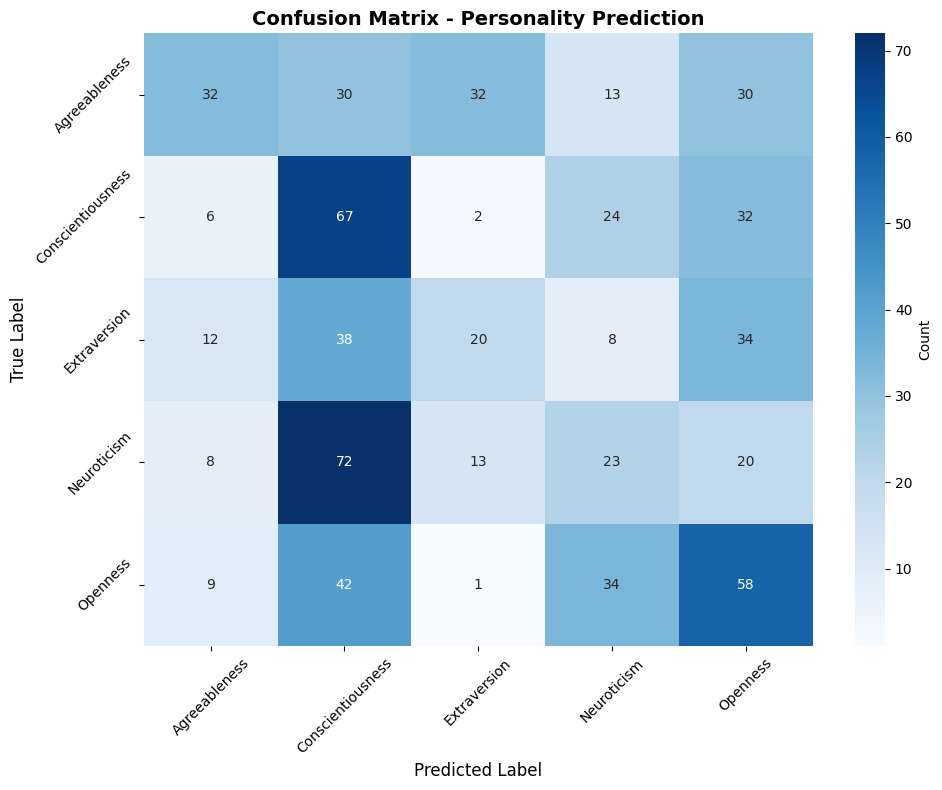

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=personality_classes, 
            yticklabels=personality_classes,
            ax=ax, cbar_kws={'label': 'Count'})
ax.set_ylabel('True Label', fontsize=12)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_title('Confusion Matrix - Personality Prediction', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()

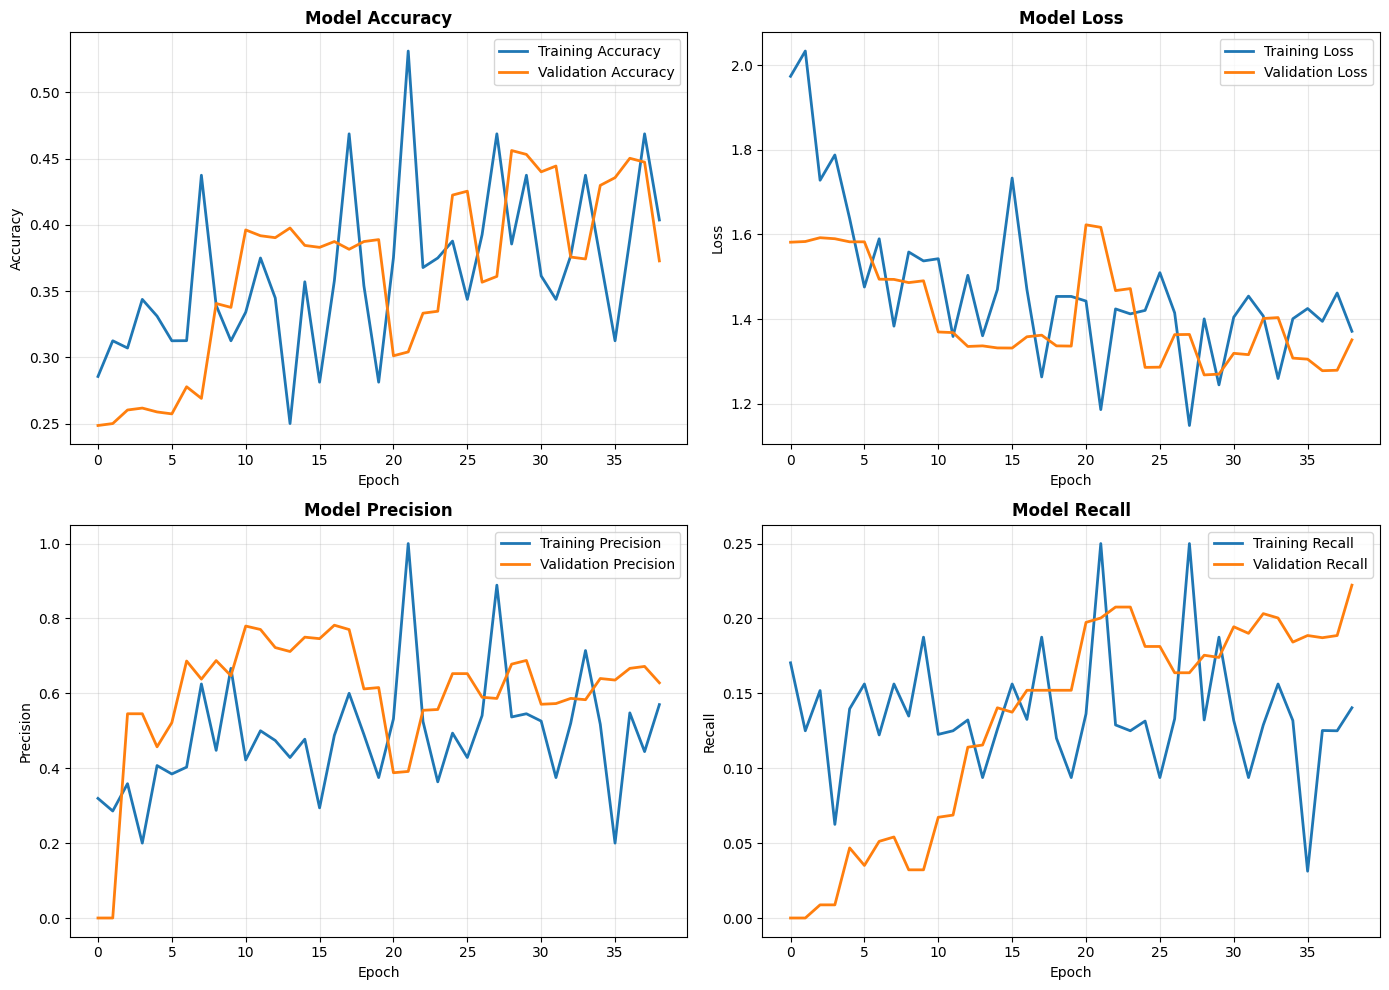

In [16]:
# Plot training history
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
axes[0, 0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0, 0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0, 0].set_title('Model Accuracy', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Loss
axes[0, 1].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 1].set_title('Model Loss', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Precision
axes[1, 0].plot(history.history['precision'], label='Training Precision', linewidth=2)
axes[1, 0].plot(history.history['val_precision'], label='Validation Precision', linewidth=2)
axes[1, 0].set_title('Model Precision', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Recall
axes[1, 1].plot(history.history['recall'], label='Training Recall', linewidth=2)
axes[1, 1].plot(history.history['val_recall'], label='Validation Recall', linewidth=2)
axes[1, 1].set_title('Model Recall', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

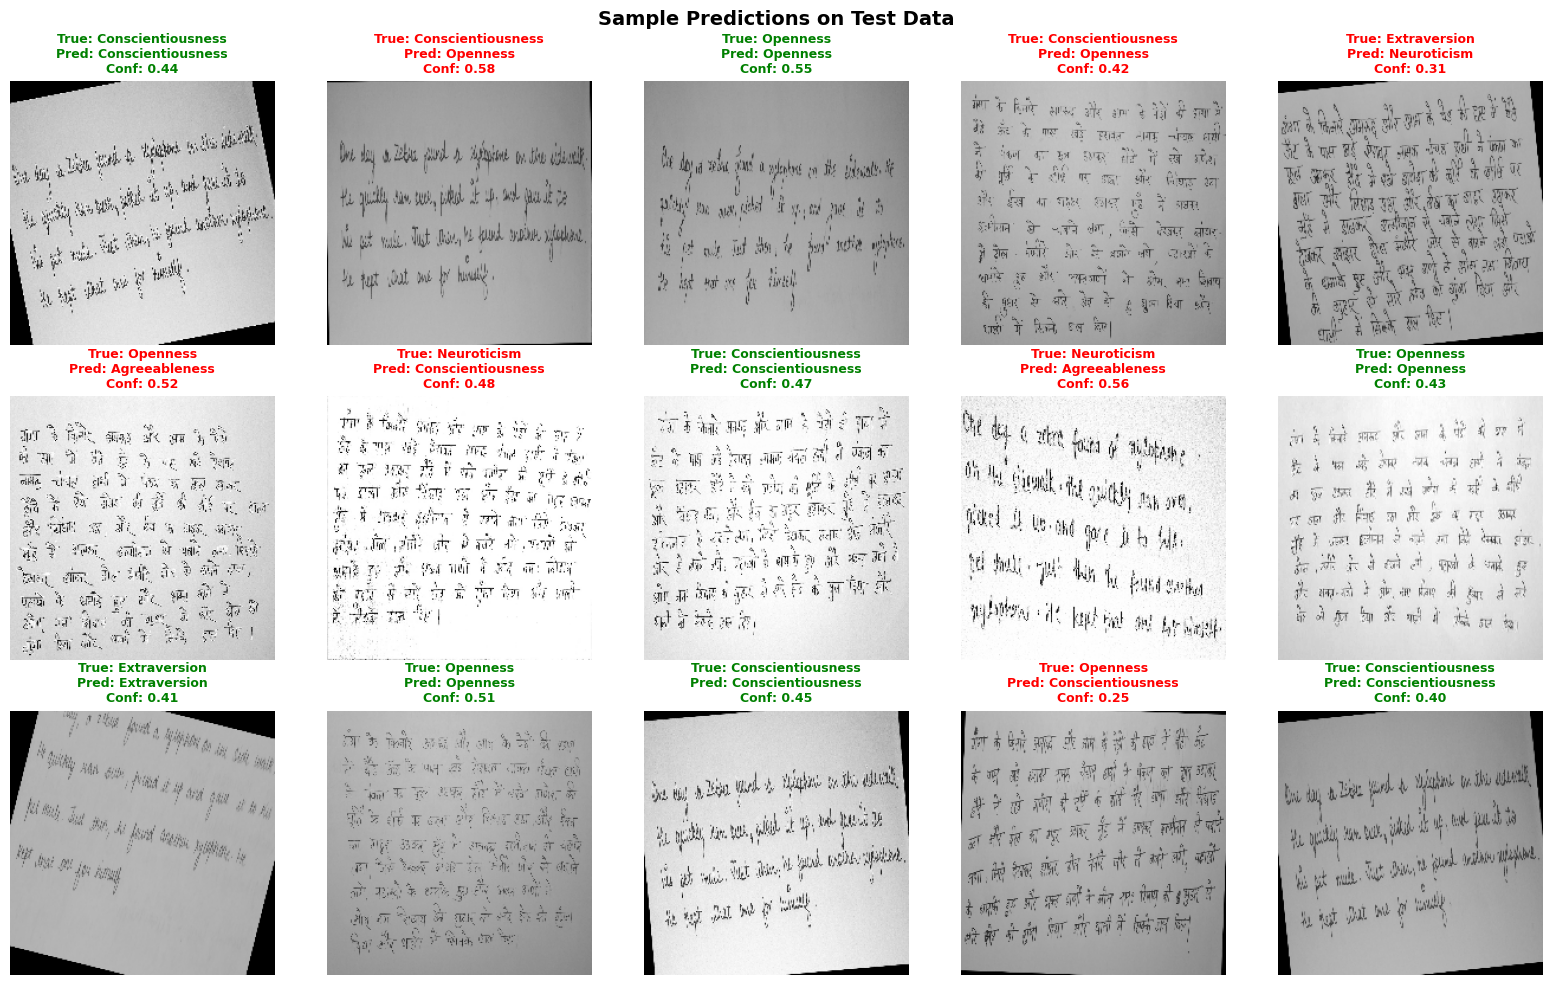

In [17]:
# Visualize predictions on test samples
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
fig.suptitle('Sample Predictions on Test Data', fontsize=14, fontweight='bold')

# Select random test samples
sample_indices = np.random.choice(len(test_images_rgb), 15, replace=False)

for idx, sample_idx in enumerate(sample_indices):
    ax = axes[idx // 5, idx % 5]
    
    # Display image
    img = test_images_rgb[sample_idx]
    if img.shape[-1] == 3:
        ax.imshow(img)
    else:
        ax.imshow(img[:, :, 0], cmap='gray')
    
    # Get prediction
    true_label = personality_classes[y_test_true[sample_idx]]
    pred_label = personality_classes[y_pred[sample_idx]]
    pred_confidence = np.max(y_pred_probs[sample_idx])
    
    # Set title with prediction
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f'True: {true_label}\nPred: {pred_label}\nConf: {pred_confidence:.2f}', 
                 fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Make Predictions on New Handwriting Samples

Create a function to preprocess and predict personality from new handwriting images, display prediction probabilities for each personality class.

In [18]:
def predict_personality(image_path, model, personality_classes):
    """
    Predict personality trait from a handwriting image
    
    Args:
        image_path: Path to the handwriting image
        model: Trained Keras model
        personality_classes: List of personality class names
    
    Returns:
        Dictionary with predictions and confidence scores
    """
    # Read and preprocess image
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError(f"Could not load image from {image_path}")
    
    # Resize to 224x224
    img_resized = cv2.resize(img, (224, 224))
    
    # Normalize
    img_normalized = img_resized.astype('float32') / 255.0
    
    # Convert grayscale to RGB
    img_rgb = np.stack([img_normalized] * 3, axis=-1)
    
    # Add batch dimension
    img_batch = np.expand_dims(img_rgb, axis=0)
    
    # Make prediction
    prediction = model.predict(img_batch, verbose=0)[0]
    predicted_class_idx = np.argmax(prediction)
    predicted_class = personality_classes[predicted_class_idx]
    confidence = prediction[predicted_class_idx]
    
    # Create result dictionary
    result = {
        'predicted_personality': predicted_class,
        'confidence': confidence,
        'probabilities': {
            personality_classes[i]: float(prediction[i]) 
            for i in range(len(personality_classes))
        }
    }
    
    return result

# Test the prediction function on a sample from test set
print("Testing prediction function on random test samples...\n")

for i in range(3):
    # Get a random test image
    sample_idx = np.random.randint(0, len(test_images_rgb))
    
    # Get true label
    true_label = personality_classes[y_test_true[sample_idx]]
    pred_probs = y_pred_probs[sample_idx]
    
    # Display results
    print(f"Sample {i+1}:")
    print(f"True Personality: {true_label}")
    print(f"Predicted Personality: {personality_classes[np.argmax(pred_probs)]}")
    print(f"Confidence Scores:")
    for j, personality in enumerate(personality_classes):
        print(f"  {personality}: {pred_probs[j]:.4f}")
    print()

Testing prediction function on random test samples...

Sample 1:
True Personality: Conscientiousness
Predicted Personality: Conscientiousness
Confidence Scores:
  Agreeableness: 0.0915
  Conscientiousness: 0.4250
  Extraversion: 0.1425
  Neuroticism: 0.3135
  Openness: 0.0275

Sample 2:
True Personality: Neuroticism
Predicted Personality: Openness
Confidence Scores:
  Agreeableness: 0.2036
  Conscientiousness: 0.1979
  Extraversion: 0.0330
  Neuroticism: 0.2168
  Openness: 0.3487

Sample 3:
True Personality: Extraversion
Predicted Personality: Openness
Confidence Scores:
  Agreeableness: 0.0713
  Conscientiousness: 0.1367
  Extraversion: 0.0060
  Neuroticism: 0.1232
  Openness: 0.6628



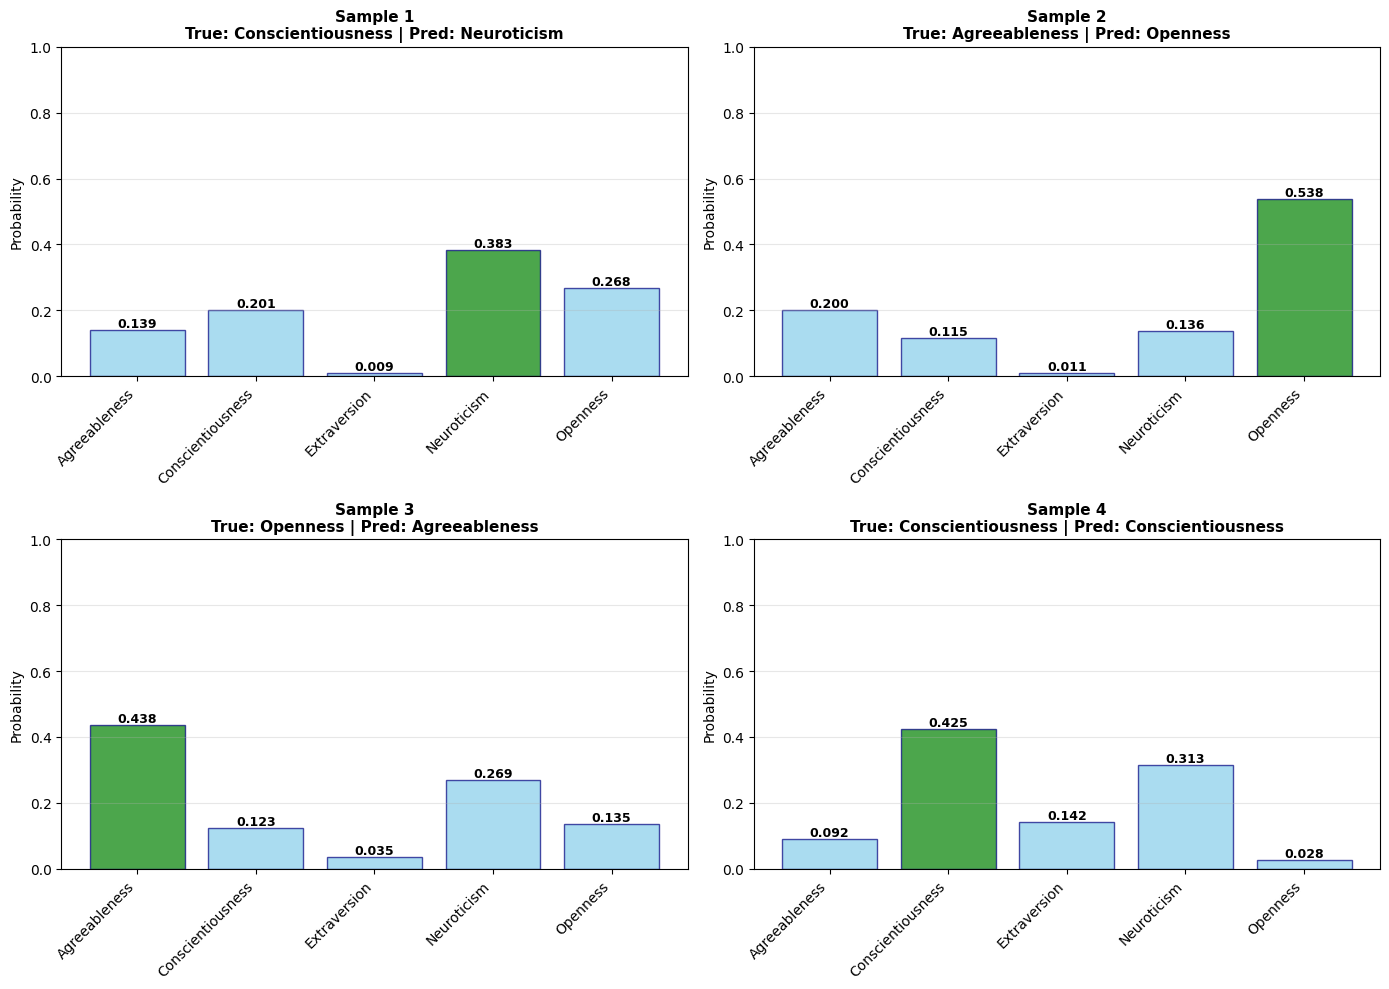

In [19]:
# Visualize prediction probabilities for a sample
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx in range(4):
    ax = axes[idx // 2, idx % 2]
    
    # Select a random test sample
    sample_idx = np.random.randint(0, len(test_images_rgb))
    
    # Get prediction probabilities
    probs = y_pred_probs[sample_idx]
    true_label = personality_classes[y_test_true[sample_idx]]
    pred_label = personality_classes[np.argmax(probs)]
    
    # Create bar plot
    colors = ['green' if p == np.max(probs) else 'skyblue' for p in probs]
    bars = ax.bar(personality_classes, probs, color=colors, edgecolor='navy', alpha=0.7)
    
    # Add value labels on bars
    for bar, prob in zip(bars, probs):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{prob:.3f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_ylabel('Probability', fontsize=10)
    ax.set_title(f'Sample {idx+1}\nTrue: {true_label} | Pred: {pred_label}', 
                 fontsize=11, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [20]:
# Save the trained model
model_save_path = 'personality_prediction_resnet_model.h5'
best_model.save(model_save_path)
print(f"Model saved to '{model_save_path}'")

# Save a summary report
summary_report = f"""
=== HANDWRITING-BASED PERSONALITY DETECTION MODEL ===

Model Architecture: ResNet50 + Custom Dense Layers
- Base Model: ResNet50 (ImageNet pre-trained)
- Custom Layers: 3 Dense layers with Dropout and BatchNormalization
- Total Parameters: {best_model.count_params():,}

Dataset Information:
- Total Training Samples: {len(X_train)}
- Total Validation Samples: {len(X_val)}
- Total Test Samples: {len(test_images_rgb)}
- Number of Classes: {len(personality_classes)}
- Classes: {', '.join(personality_classes)}

Performance Metrics:
- Test Accuracy: {test_accuracy:.4f}
- Test Precision: {test_precision:.4f}
- Test Recall: {test_recall:.4f}
- Weighted F1-Score: {f1:.4f}

Training Details:
- Optimizer: Adam (lr=0.001 initial, reduced to 1e-5 for fine-tuning)
- Loss Function: Categorical Crossentropy
- Batch Size: 32 (initial), 16 (fine-tuning)
- Max Epochs: 50 (initial) + 20 (fine-tuning)
- Early Stopping: Enabled (patience=10)
- Learning Rate Scheduling: Enabled (factor=0.5, patience=5)

Per-Class Performance:
"""

for i, personality in enumerate(personality_classes):
    class_mask = y_test_true == i
    if np.sum(class_mask) > 0:
        class_accuracy = np.sum((y_pred[class_mask] == i)) / np.sum(class_mask)
        summary_report += f"\n{personality}:\n"
        summary_report += f"  Accuracy: {class_accuracy:.4f}\n"
        summary_report += f"  Samples: {np.sum(class_mask)}\n"

# Save report to file
with open('model_performance_report.txt', 'w') as f:
    f.write(summary_report)

print("Performance report saved to 'model_performance_report.txt'")
print("\n" + summary_report)

Model saved to 'personality_prediction_resnet_model.h5'
Performance report saved to 'model_performance_report.txt'


=== HANDWRITING-BASED PERSONALITY DETECTION MODEL ===

Model Architecture: ResNet50 + Custom Dense Layers
- Base Model: ResNet50 (ImageNet pre-trained)
- Custom Layers: 3 Dense layers with Dropout and BatchNormalization
- Total Parameters: 24,805,253

Dataset Information:
- Total Training Samples: 2732
- Total Validation Samples: 684
- Total Test Samples: 660
- Number of Classes: 5
- Classes: Agreeableness, Conscientiousness, Extraversion, Neuroticism, Openness

Performance Metrics:
- Test Accuracy: 0.3030
- Test Precision: 0.3000
- Test Recall: 0.0864
- Weighted F1-Score: 0.2922

Training Details:
- Optimizer: Adam (lr=0.001 initial, reduced to 1e-5 for fine-tuning)
- Loss Function: Categorical Crossentropy
- Batch Size: 32 (initial), 16 (fine-tuning)
- Max Epochs: 50 (initial) + 20 (fine-tuning)
- Early Stopping: Enabled (patience=10)
- Learning Rate Scheduling: Enable